# Women's Clothing E-Commerce

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.ensemble import RandomForestClassifier

In [12]:
df = pd.read_csv("womens_clothing.csv")

In [13]:
df.head()

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,868,39,Disappointed with fit,"Slightly looser than expected around the bust,...",5,1,0,General,Tops,Skirts
1,829,37,No Title Provided,Material feels premium and holds up very well ...,3,0,1,General,Intimate,Lounge
2,831,81,Flattering cut,"Slightly looser than expected around the bust,...",5,1,0,Initmates,Intimate,Blouses
3,872,34,No Title Provided,Material feels premium and holds up very well ...,5,1,1,Initmates,Jackets,Sweaters
4,868,29,No Title Provided,No Review Text Provided,5,1,12,General Petite,Intimate,Skirts


In [14]:
df.tail()

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
1495,868,38,Great quality,"The color is true to the online photo, but the...",1,0,4,General Petite,Dresses,Sweaters
1496,863,36,Runs a bit small,"The color is true to the online photo, but the...",1,0,4,Initmates,Dresses,Pants
1497,1110,70,Great quality,Absolutely love the fit and texture of this pi...,4,1,1,General Petite,Intimate,Knits
1498,862,36,Comfortable and stylish,Material feels premium and holds up very well ...,3,1,1,General,Dresses,Skirts
1499,872,74,Comfortable and stylish,"The color is true to the online photo, but the...",1,0,0,General,Dresses,Dresses


In [15]:
df.shape

(1500, 10)

In [16]:
df.columns

Index(['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='object')

In [17]:
df.dtypes

Clothing ID                 int64
Age                         int64
Title                      object
Review Text                object
Rating                      int64
Recommended IND             int64
Positive Feedback Count     int64
Division Name              object
Department Name            object
Class Name                 object
dtype: object

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Clothing ID              1500 non-null   int64 
 1   Age                      1500 non-null   int64 
 2   Title                    1500 non-null   object
 3   Review Text              1500 non-null   object
 4   Rating                   1500 non-null   int64 
 5   Recommended IND          1500 non-null   int64 
 6   Positive Feedback Count  1500 non-null   int64 
 7   Division Name            1500 non-null   object
 8   Department Name          1500 non-null   object
 9   Class Name               1500 non-null   object
dtypes: int64(5), object(5)
memory usage: 117.3+ KB


In [19]:
df.describe()

,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,951.251333,50.282667,4.199333,0.784667,2.367333
std,116.850966,19.092628,1.114343,0.411190,2.768184
min,829.000000,18.000000,1.000000,0.000000,0.000000
25%,862.000000,34.000000,4.000000,1.000000,0.000000
50%,872.000000,50.000000,5.000000,1.000000,2.000000
75%,1080.000000,66.000000,5.000000,1.000000,3.000000
max,1110.000000,84.000000,5.000000,1.000000,20.000000


In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df = df.drop_duplicates()

In [22]:
df.isnull().sum()

Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Recommended IND            0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64

In [23]:
df['Title'] = df['Title'].fillna("No Title Provided")
df['Review Text'] = df['Review Text'].fillna("No Review Text Provided")
df['Division Name'] = df['Division Name'].fillna(df['Division Name'].mode()[0])
df['Department Name'] = df['Department Name'].fillna(df['Department Name'].mode()[0])
df['Class Name'] = df['Class Name'].fillna(df['Class Name'].mode()[0])
df['Age'] = df['Age'].fillna(df['Age'].median())

In [24]:
df = df.dropna()

In [25]:
df.isnull().sum()

Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Recommended IND            0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64

In [26]:
filtered_df = df[(df['Rating'] >= 4) & (df['Recommended IND'] == 1)]
filtered_df.head()

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,868,39,Disappointed with fit,"Slightly looser than expected around the bust,...",5,1,0,General,Tops,Skirts
2,831,81,Flattering cut,"Slightly looser than expected around the bust,...",5,1,0,Initmates,Intimate,Blouses
3,872,34,No Title Provided,Material feels premium and holds up very well ...,5,1,1,Initmates,Jackets,Sweaters
4,868,29,No Title Provided,No Review Text Provided,5,1,12,General Petite,Intimate,Skirts
5,863,39,Great quality,Absolutely love the fit and texture of this pi...,5,1,0,General Petite,Dresses,Blouses


In [27]:
grouped_mean = df.groupby('Department Name')['Rating'].mean()
grouped_mean

Department Name
Bottoms     4.146718
Dresses     4.169675
Intimate    4.176955
Jackets     4.223684
Tops        4.273469
Trend       4.213710
Name: Rating, dtype: float64

In [28]:
grouped_agg = df.groupby('Department Name').agg({
    'Rating': ['count', 'mean', 'std'],
    'Age': ['mean', 'median'],
    'Positive Feedback Count': 'sum'
})
grouped_agg

Rating                            Age         \
                 count      mean       std       mean median   
Department Name                                                
Bottoms            259  4.146718  1.100431  49.274131   49.0   
Dresses            277  4.169675  1.162558  51.173285   50.0   
Intimate           243  4.176955  1.115983  48.390947   47.0   
Jackets            228  4.223684  1.125578  51.622807   52.0   
Tops               245  4.273469  1.087706  51.722449   51.0   
Trend              248  4.213710  1.094102  49.540323   49.0   

                Positive Feedback Count  
                                    sum  
Department Name                          
Bottoms                             535  
Dresses                             683  
Intimate                            545  
Jackets                             631  
Tops                                549  
Trend                               608

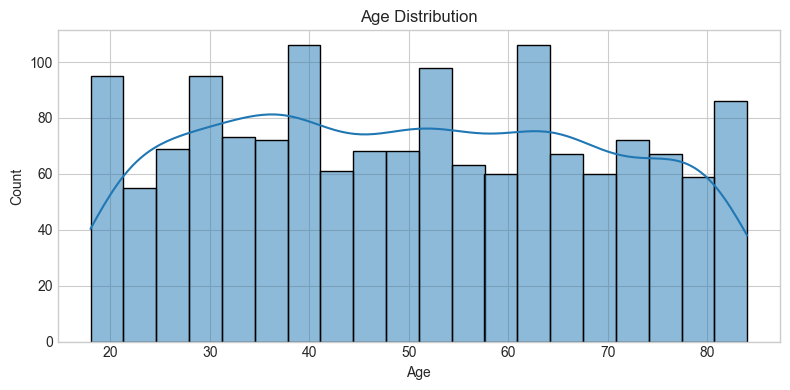

In [29]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'], kde=True, bins=20)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

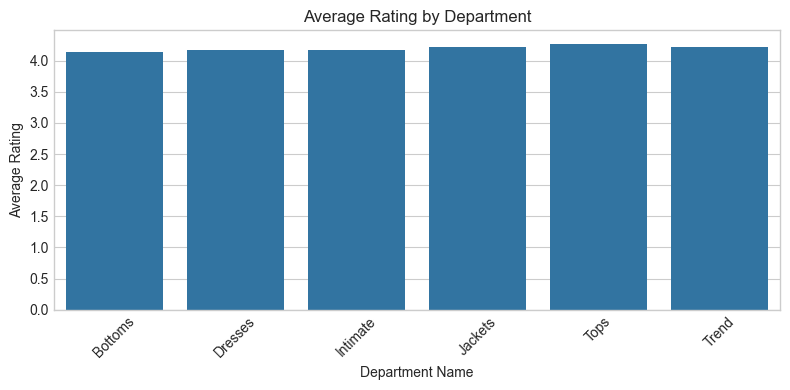

In [33]:
plt.figure(figsize=(8, 4))
sns.barplot(x=grouped_mean.index, y=grouped_mean.values)
plt.title("Average Rating by Department")
plt.xlabel("Department Name")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

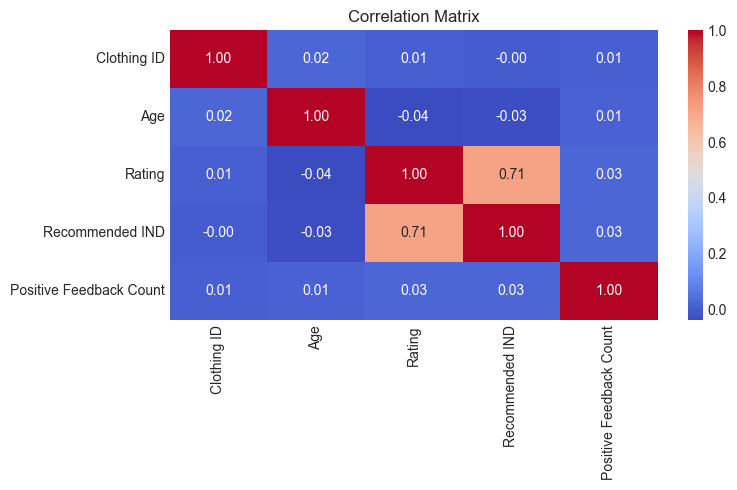

In [36]:
plt.figure(figsize=(8, 5))
numeric_cols = df.select_dtypes(include=['number']).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [38]:
df.to_csv("cleaned_womens_clothing.csv", index=False)

In [39]:
grouped_agg.to_csv("department_analysis.csv")

In [50]:
num_cols = ["Age", "Rating", "Recommended IND", "Positive Feedback Count"]

scaler = StandardScaler()
scaled_num = scaler.fit_transform(df_clean[num_cols])

knn_imputer = KNNImputer(n_neighbors=5, weights="distance")
imputed_scaled = knn_imputer.fit_transform(scaled_num)

df_clean[num_cols] = scaler.inverse_transform(imputed_scaled)
df_clean["Age"] = df_clean["Age"].round().astype(int)


cat_targets = ["Division Name", "Department Name", "Class Name"]
predictor_features = ["Clothing ID", "Age", "Rating", "Recommended IND"]

for target_col in cat_targets:
    missing_mask = df_clean[target_col].isnull()
    
    if missing_mask.sum() > 0:
        train_data = df_clean[~missing_mask]
        predict_data = df_clean[missing_mask]
        
        X_train = train_data[predictor_features]
        y_train = train_data[target_col]
        X_pred = predict_data[predictor_features]
        
        clf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
        clf.fit(X_train, y_train)
        
        df_clean.loc[missing_mask, target_col] = clf.predict(X_pred)

assert df_clean.isnull().sum().sum() == 0, "Missing values still remain!"
df_clean.to_csv("womens_clothing_fully_imputed.csv", index=False)
print("Pipeline complete. Total remaining missing values: 0")

Pipeline complete. Total remaining missing values: 0


In [51]:
df = pd.read_csv('cleaned_womens_clothing.csv')
df.head(4)

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,868,39,Disappointed with fit,"Slightly looser than expected around the bust,...",5,1,0,General,Tops,Skirts
1,829,37,No Title Provided,Material feels premium and holds up very well ...,3,0,1,General,Intimate,Lounge
2,831,81,Flattering cut,"Slightly looser than expected around the bust,...",5,1,0,Initmates,Intimate,Blouses
3,872,34,No Title Provided,Material feels premium and holds up very well ...,5,1,1,Initmates,Jackets,Sweaters
